# Data exploration

Inspect recorded values, distributions, missingness, and relationships.
Missing entries remain visible in the analysis.

Run this notebook from the `notebooks/` directory with Python and pandas installed. The input is `../data/raw/student_data.csv`. Each notebook loads the input independently. The previous user environment used Python 3.14.10 and pandas 3.1.1. Execution outputs below record the validation runtime.

### Environment check

The Python interpreter, version, working directory, and pandas version
are displayed to record the execution environment.

In [38]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Data loading and initial dimensions

The CSV is loaded into the DataFrame `data`.
The loading options preserve the literal education category "None"
while treating empty fields as missing values.

A table of student variables is created by excluding the exported row index.

In [39]:
data = pd.read_csv(
    '../data/raw/student_data.csv',
    keep_default_na=False,
    na_values=['']
)

In [40]:
student_data = data.drop(columns=['Unnamed: 0'])

student_data.shape

(649, 33)

---

### Duplicate records

Records are checked for identical values across the student variables.
The exported row index is excluded because its unique values could
hide otherwise identical records.

In [41]:
duplicate_count = student_data.duplicated().sum()

duplicate_count

np.int64(0)

---

### Missing-value analysis

Missing values are counted for each column to assess data completeness.
The distribution of recorded values is also inspected, including missing
entries, to support later preprocessing decisions.

In [42]:
missing_counts = student_data.isna().sum()
missing_percentages = (missing_counts / len(student_data) * 100).round(2)

missing_summary = pd.DataFrame({
    'Missing count': missing_counts,
    'Missing (%)': missing_percentages
})

missing_summary

,Missing count,Missing (%)
school,1,0.15
sex,10,1.54
age,0,0.00
address,17,2.62
famsize,3,0.46
Pstatus,28,4.31
Medu,27,4.16
Fedu,19,2.93
Mjob,6,0.92
Fjob,18,2.77


### Column types and structure

Inspect each column's stored data type and number of non-missing
values before reviewing variable roles and distributions.

In [43]:
student_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   school      648 non-null    str    
 1   sex         639 non-null    str    
 2   age         649 non-null    int64  
 3   address     632 non-null    str    
 4   famsize     646 non-null    float64
 5   Pstatus     621 non-null    str    
 6   Medu        622 non-null    str    
 7   Fedu        630 non-null    str    
 8   Mjob        643 non-null    str    
 9   Fjob        631 non-null    str    
 10  reason      642 non-null    str    
 11  guardian    641 non-null    str    
 12  traveltime  638 non-null    float64
 13  studytime   635 non-null    float64
 14  failures    98 non-null     float64
 15  schoolsup   619 non-null    str    
 16  famsup      642 non-null    str    
 17  paid        618 non-null    str    
 18  activities  618 non-null    str    
 19  nursery     629 non-null    str    
 20 

### Numerical summary

Summary statistics are inspected to understand the distribution and
range of numerical columns and identify values requiring investigation.

In [44]:
student_data.describe()

,age,famsize,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,646.000000,638.000000,635.000000,98.000000,625.00000,629.000000,618.000000,625.000000,622.000000,632.000000,389.000000,649.000000,649.000000,649.000000
mean,16.744222,4.978328,18.213166,242.206299,1.428571,3.92480,3.193959,3.192557,1.508800,2.284566,3.526899,5.889460,11.399076,11.570108,11.906009
std,1.218138,2.817359,19.951079,235.969842,0.717958,0.95698,1.051490,1.179296,0.930434,1.287017,1.451565,4.682234,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,0.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
25%,16.000000,3.000000,6.000000,99.500000,1.000000,4.00000,3.000000,2.000000,1.000000,1.000000,2.000000,2.000000,10.000000,10.000000,10.000000
50%,17.000000,5.000000,13.000000,186.000000,1.000000,4.00000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,12.000000
75%,18.000000,7.000000,25.000000,282.500000,2.000000,5.00000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,9.000000,144.000000,1465.000000,3.000000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


### Categorical summary

Categorical columns are inspected to identify the number of distinct
categories, the most frequent category, and its frequency.

In [45]:
student_data.describe(include=['str']).T

,count,unique,top,freq
school,648,2,GP,422
sex,639,2,F,377
address,632,2,U,443
Pstatus,621,2,T,544
Medu,622,5,Middle School Education,179
Fedu,630,5,Middle School Education,203
Mjob,643,5,other,254
Fjob,631,5,other,358
reason,642,4,course,279
guardian,641,3,mother,450


---

### Correlation between numerical features

A Pearson correlation matrix is calculated for the numerical features
to examine the direction and strength of linear relationships.

Each coefficient uses students with recorded values for both features.
The number of observations can therefore differ between comparisons.

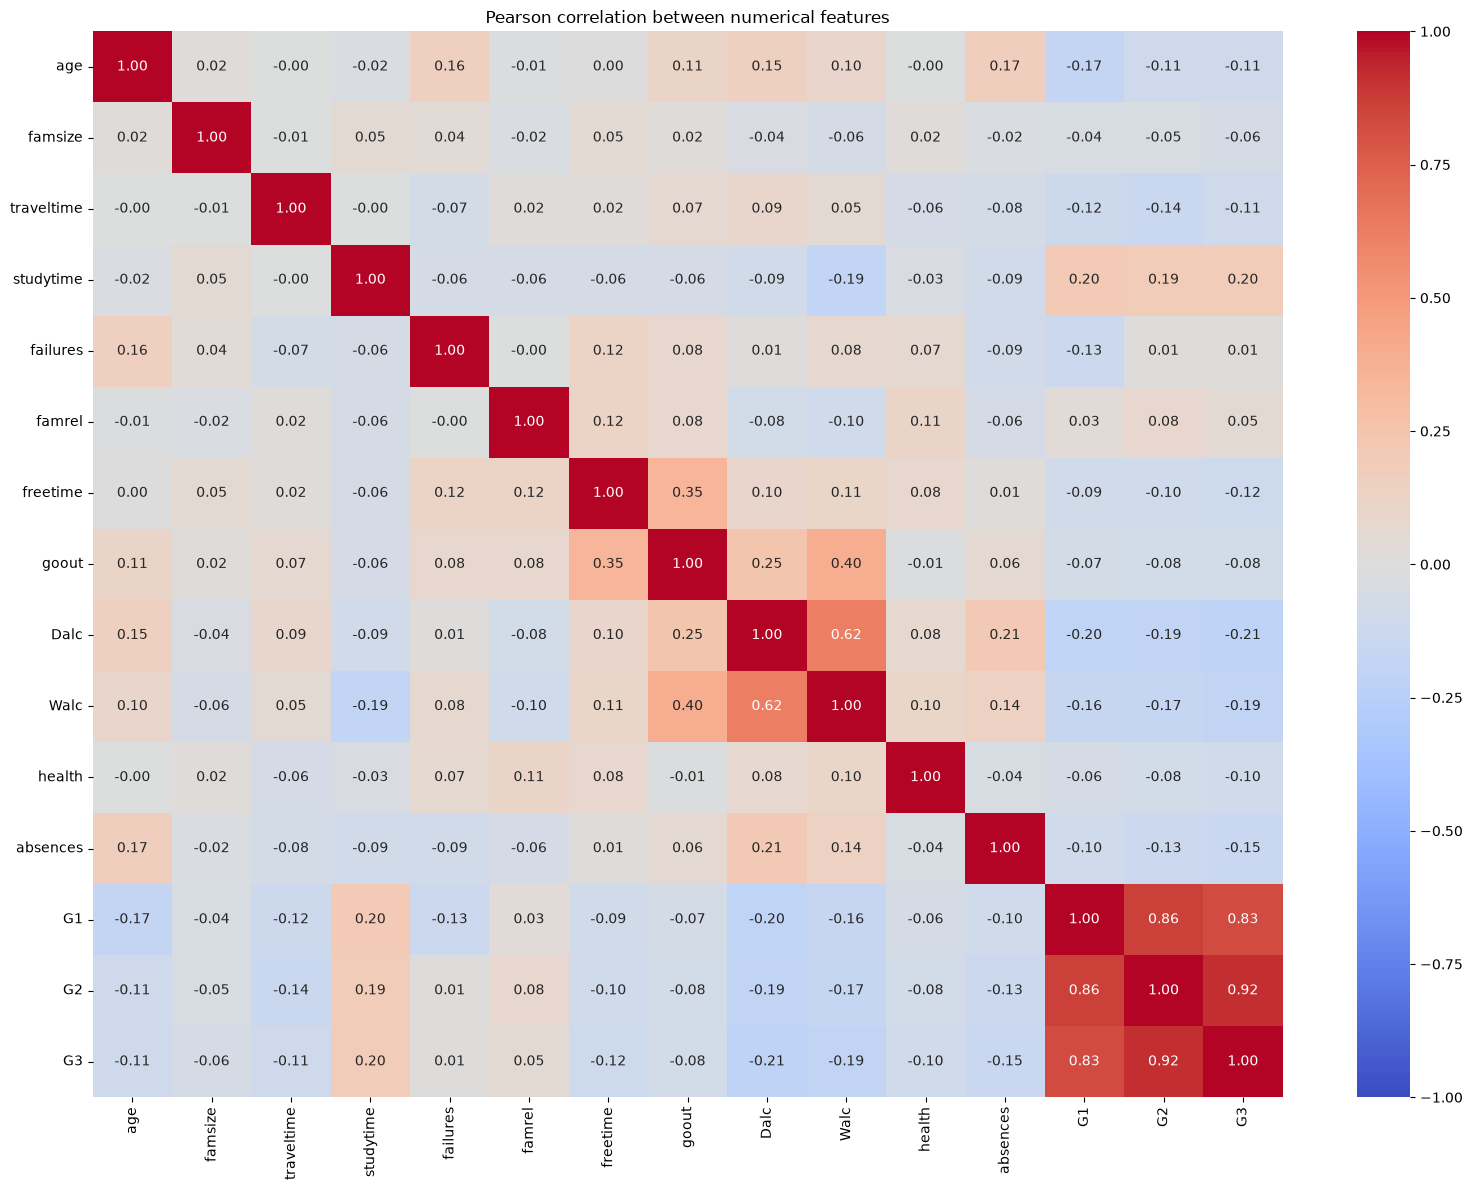

In [46]:
correlation_matrix = student_data.corr(numeric_only=True)

plt.figure(figsize=(16, 12))

sns.heatmap(
    data=correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Pearson correlation between numerical features')
plt.tight_layout()
plt.show()

### Correlation between binary and rating features

Yes/No responses are represented numerically as 1 and 0 in a separate
analysis copy. The rating features retain their existing 1–5 values.

Spearman correlations examine associations between these features.
Missing responses are excluded separately for each pair.

### Correlation between Yes/No features

Yes/No responses are encoded as 1 and 0 in a separate analysis copy.
Pearson correlations examine associations between the binary features.
Missing responses are excluded separately for each pair.

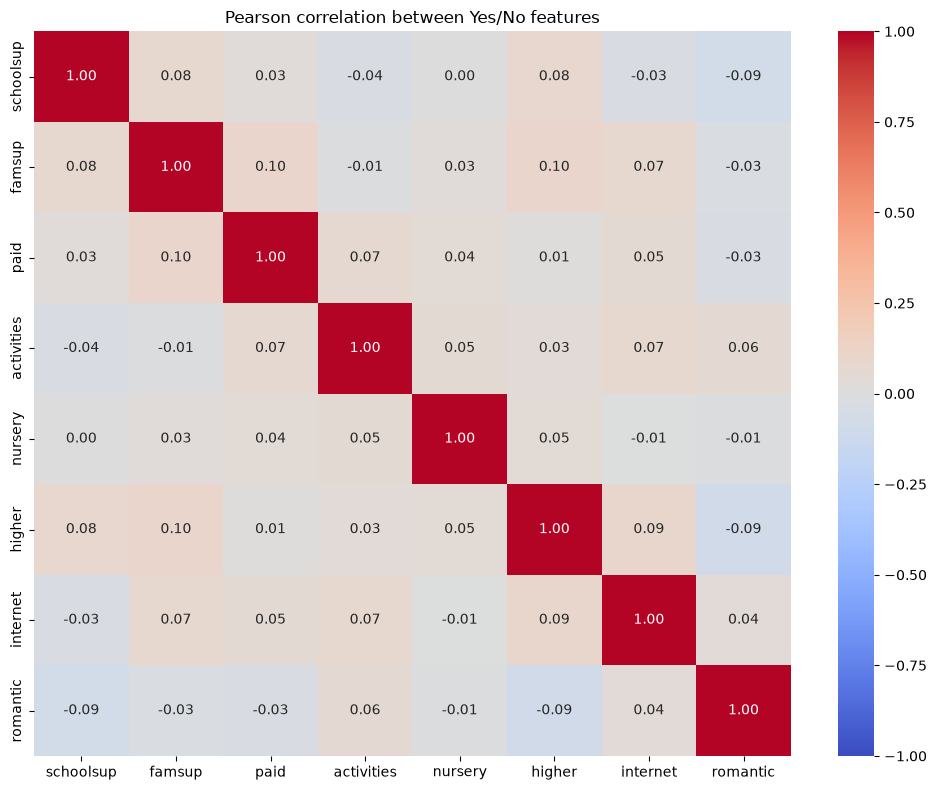

In [47]:
yes_no_columns = [
    'schoolsup', 'famsup', 'paid', 'activities',
    'nursery', 'higher', 'internet', 'romantic'
]

yes_no_numeric = student_data[yes_no_columns].copy()

yes_no_numeric = student_data[yes_no_columns].copy()

for column in yes_no_columns:
    yes_no_numeric[column] = yes_no_numeric[column].map({
        'yes': 1,
        'no': 0
    })

yes_no_correlation = yes_no_numeric.corr(method='pearson')

plt.figure(figsize=(10, 8))

sns.heatmap(
    yes_no_correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Pearson correlation between Yes/No features')
plt.tight_layout()
plt.show()

### Correlation between rating features

Spearman correlations examine associations between the ordered
1–5 ratings. Missing responses are excluded separately for each pair.

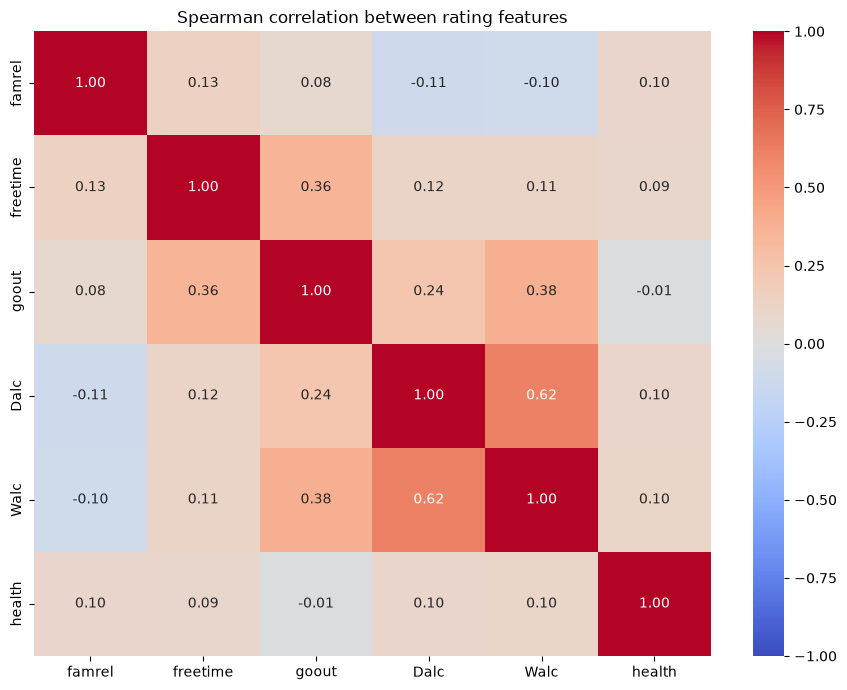

In [48]:
rating_columns = [
    'famrel', 'freetime', 'goout',
    'Dalc', 'Walc', 'health'
]

rating_correlation = student_data[rating_columns].corr(
    method='spearman'
)

rating_correlation = student_data[rating_columns].corr(
    method='spearman'
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    rating_correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Spearman correlation between rating features')
plt.tight_layout()
plt.show()

### Distribution of categorical features

The percentage of students in each category is displayed for every
categorical feature. Missing responses are included in the percentages.

In [49]:
yes_no_columns = [
    'schoolsup', 'famsup', 'paid', 'activities',
    'nursery', 'higher', 'internet', 'romantic'
]

rating_columns = [
    'famrel', 'freetime', 'goout',
    'Dalc', 'Walc', 'health'
]

categorical_columns = student_data.select_dtypes(
    include=['str', 'object']
).columns

remaining_columns = categorical_columns.drop(yes_no_columns)

In [50]:
yes_no_percentages = pd.DataFrame(index=yes_no_columns)

for column in yes_no_columns:
    yes_no_percentages.loc[column, 'Yes'] = (
        student_data[column].eq('yes').sum() / len(student_data) * 100
    )
    yes_no_percentages.loc[column, 'No'] = (
        student_data[column].eq('no').sum() / len(student_data) * 100
    )
    yes_no_percentages.loc[column, 'Missing'] = (
        student_data[column].isna().sum() / len(student_data) * 100
    )

display(yes_no_percentages.round(2))

,Yes,No,Missing
schoolsup,10.17,85.21,4.62
famsup,60.40,38.52,1.08
paid,5.55,89.68,4.78
activities,45.92,49.31,4.78
nursery,77.97,18.95,3.08
higher,86.59,10.17,3.24
internet,76.27,22.96,0.77
romantic,36.83,63.02,0.15


### Rating percentages

The percentage of students selecting each rating is displayed alongside
the percentage with missing responses.

In [51]:
rating_percentages = pd.DataFrame(index=rating_columns)

for column in rating_columns:
    for rating in range(1, 6):
        rating_percentages.loc[column, rating] = (
            student_data[column].eq(rating).sum() / len(student_data) * 100
        )

    rating_percentages.loc[column, 'Missing'] = (
        student_data[column].isna().sum() / len(student_data) * 100
    )

display(rating_percentages.round(2))

,1,2,3,4,5,Missing
famrel,3.24,4.47,15.10,47.00,26.50,3.70
freetime,6.63,15.56,37.60,26.66,10.48,3.08
goout,7.24,20.80,29.74,21.26,16.18,4.78
Dalc,66.56,18.18,6.47,2.47,2.62,3.70
Walc,36.36,22.34,17.26,13.25,6.63,4.16
health,13.87,11.56,18.49,16.33,37.13,2.62


### Remaining categorical percentages

The remaining categorical features are displayed with one row per feature
and one column per category. Empty cells indicate categories that do not
apply to that feature.

In [52]:
for column in remaining_columns:
    remaining_percentages = (
        student_data[column]
        .fillna('Missing')
        .value_counts(normalize=True)
        .mul(100)
        .to_frame(name=column)
        .T
    )

    display(remaining_percentages.round(2))

school,GP,MS,Missing
school,65.02,34.82,0.15


sex,F,M,Missing
sex,58.09,40.37,1.54


address,U,R,Missing
address,68.26,29.12,2.62


Pstatus,T,A,Missing
Pstatus,83.82,11.86,4.31


Medu,Middle School Education,Higher Education,Primary Education,Secondary Education,Missing,None
Medu,27.58,25.73,21.57,20.03,4.16,0.92


Fedu,Middle School Education,Primary Education,Secondary Education,Higher Education,Missing,None
Fedu,31.28,26.19,19.57,18.95,2.93,1.08


Mjob,other,at_home,services,teacher,health,Missing
Mjob,39.14,20.8,20.8,10.94,7.4,0.92


Fjob,other,services,at_home,teacher,health,Missing
Fjob,55.16,26.81,6.32,5.55,3.39,2.77


reason,course,home,reputation,other,Missing
reason,42.99,22.96,21.88,11.09,1.08


guardian,mother,father,other,Missing
guardian,69.34,23.11,6.32,1.23


---

### Parental education and occupation

Parental education and occupation are examined together to identify
common combinations and records requiring further investigation.

In [53]:
mother_education_job = pd.crosstab(
    student_data['Medu'].fillna('Missing'),
    student_data['Mjob'].fillna('Missing')
)

mother_education_job

Mjob,Missing,at_home,health,other,services,teacher
Medu,,,,,,
Higher Education,2,3,36,32,28,66
Middle School Education,3,40,5,88,43,0
Missing,1,3,0,12,8,3
None,0,3,0,3,0,0
Primary Education,0,66,2,66,6,0
Secondary Education,0,20,5,53,50,2


In [54]:
father_education_job = pd.crosstab(
    student_data['Fedu'].fillna('Missing'),
    student_data['Fjob'].fillna('Missing')
)

father_education_job

Fjob,Missing,at_home,health,other,services,teacher
Fedu,,,,,,
Higher Education,1,3,16,43,27,33
Middle School Education,2,14,2,127,58,0
Missing,1,4,2,7,4,1
None,1,1,0,5,0,0
Primary Education,7,13,0,107,42,1
Secondary Education,6,6,2,69,43,1


### Parental status and guardian

Parental living arrangements are compared with the recorded guardian.

In [55]:
parental_status_guardian = pd.crosstab(
    student_data['Pstatus'].fillna('Missing'),
    student_data['guardian'].fillna('Missing')
)

parental_status_guardian

guardian,Missing,father,mother,other
Pstatus,,,,
A,0,6,62,9
Missing,0,10,16,2
T,8,134,372,30


### Family size and parental status

Family-size values are compared with parental living arrangements.

In [56]:
family_size_parental_status = pd.crosstab(
    student_data['famsize'].astype('string').fillna('Missing'),
    student_data['Pstatus'].fillna('Missing')
)

family_size_parental_status

Pstatus,A,Missing,T
famsize,,,
0.0,13,3,41
1.0,15,2,31
2.0,10,1,27
3.0,9,2,37
4.0,4,0,75
5.0,3,4,81
6.0,8,2,52
7.0,5,1,61
8.0,7,5,68


### Family size and guardian

Family-size values are compared with the recorded guardian.

In [57]:
family_size_guardian = pd.crosstab(
    student_data['famsize'].astype('string').fillna('Missing'),
    student_data['guardian'].fillna('Missing')
)

family_size_guardian

guardian,Missing,father,mother,other
famsize,,,,
0.0,2,13,40,2
1.0,1,6,36,5
2.0,0,12,26,0
3.0,0,11,33,4
4.0,1,22,55,1
5.0,1,18,62,7
6.0,2,11,46,3
7.0,0,13,48,6
8.0,1,17,57,5


### Family-size 0 consistency checks

Family size 0 is examined alongside parental status and guardian information
to identify and count combinations requiring further investigation.

In [58]:
zero_family_together = (
    (student_data['famsize'] == 0) &
    (student_data['Pstatus'] == 'T')
)

zero_family_parent_guardian = (
    (student_data['famsize'] == 0) &
    student_data['guardian'].isin(['mother', 'father'])
)

one_family_together = (
    (student_data['famsize'] == 1) &
    (student_data['Pstatus'] == 'T')
)

family_combination_counts = pd.DataFrame({
    'Combination': [
        'Family size 0 and parents together',
        'Family size 0 and parent as guardian',
        'Family size 1 and parents together'
    ],
    'Records': [
        zero_family_together.sum(),
        zero_family_parent_guardian.sum(),
        one_family_together.sum()
    ]
})

family_combination_counts

,Combination,Records
0,Family size 0 and parents together,41
1,Family size 0 and parent as guardian,53
2,Family size 1 and parents together,31


### Questionable family-size combinations

Several combinations raise questions about the meaning of `famsize`.

- **Family size 0 with parents living together — 41 records.**
  A family containing the student and both parents would contain three or at
  least two people, if they share the household and are included
  in the count.

- **Family size 0 with a parent as guardian — 53 records.**
  The recorded family size excludes everyone, despite identifying
  a mother or father as responsible for the student.

- **Family size 1 with parents living together — 31 records.**
  This count is too small to include the student or only both parents
  if they live in the same household.

Parental status and guardianship do not establish household membership,
but these combinations make the family-size values questionable.

---

### Analysis of failures and absences

The distributions of previous failures and absences are inspected,
including missing entries, to investigate recorded values and the
possible meaning of blanks before deciding on a treatment.

In [59]:
student_data['failures'].value_counts(dropna=False).sort_index()

failures
1.0     69
2.0     16
3.0     13
NaN    551
Name: count, dtype: int64

In [60]:
student_data['absences'].value_counts(dropna=False).sort_index()

absences
1.0      10
2.0     108
3.0       7
4.0      88
5.0      12
6.0      46
7.0       2
8.0      41
9.0       6
10.0     21
11.0      5
12.0     12
13.0      1
14.0      8
15.0      2
16.0      9
18.0      3
21.0      2
22.0      2
24.0      1
26.0      1
30.0      1
32.0      1
NaN     260
Name: count, dtype: int64

### Interpretation of missing failures and absences

`failures` contains 551 missing values (84.9%), while `absences`
contains 260 (40.1%). Both columns contain only positive recorded
counts, with no explicit zeros.

This pattern suggests that NaN may represent zero previous failures
or absences. We can adopt this interpretation and replace missing entries
with zero during preprocessing.

---

### Travel time, residence, and school

Travel-time distributions are compared across residence types and
schools. Zero-duration journeys are inspected to identify patterns
requiring clarification.

In [61]:
travel_summary = student_data.groupby(
    ['school', 'address'],
    dropna=False
)['traveltime'].describe()

travel_summary

count       mean        std   min   25%   50%    75%    max
school address                                                             
GP     R         71.0  25.718310  30.656243   0.0   7.5  19.0  28.00  144.0
       U        332.0  13.515060  16.688810   0.0   5.0   9.0  17.00  142.0
       NaN       11.0  16.363636   9.992725   0.0  11.0  15.0  23.50   30.0
MS     R        114.0  27.315789  21.896101   0.0  16.0  25.0  33.75  135.0
       U        103.0  18.427184  13.743877   0.0   9.5  17.0  25.00   87.0
       NaN        6.0  15.666667   7.420692   7.0  10.0  15.0  20.75   26.0
NaN    U          1.0  21.000000        NaN  21.0  21.0  21.0  21.00   21.0

### Zero travel times

Zero-duration journeys are counted by school and residence type.

In [84]:
zero_travel = student_data.loc[
    student_data['traveltime'] == 0,
    ['school', 'address', 'traveltime']
]

zero_travel.groupby(
    ['school', 'address'],
    dropna=False
).size()

school  address
GP      R           1
        U          24
        NaN         1
MS      R           2
        U           1
dtype: int64

### Interpretation of zero travel times

There are 29 recorded zero-minute journeys, including 24 among urban
students at GP, 1 among urban students at MS, 3 among rural students,
and 1 with missing residence information.

The concentration among urban GP students is compatible with very short journeys rounded to zero or a school-specific practice where students live in the same building. At GP it could be an error in data recording. Should be analysed further. #(!)#

---

### Study-time distribution

Weekly study time is inspected to identify zero values and unusually
high observations requiring further investigation.

In [63]:
student_data['studytime'].describe()

count     635.000000
mean      242.206299
std       235.969842
min         0.000000
25%        99.500000
50%       186.000000
75%       282.500000
max      1465.000000
Name: studytime, dtype: float64

### Study-time intervals

Zero and missing study times are counted separately.
Positive study times are grouped into 100-minute intervals
to inspect their distribution.

In [64]:
study_intervals = pd.cut(
    student_data['studytime'],
    bins=range(0, 1501, 100)
)

study_counts = study_intervals.value_counts().sort_index()

study_summary = pd.DataFrame({
    'Students': study_counts
})

study_summary.loc['Zero study time', 'Students'] = (
    student_data['studytime'].eq(0).sum()
)

study_summary.loc['Missing', 'Students'] = (
    student_data['studytime'].isna().sum()
)

study_summary


,Students
studytime,
"(0, 100]",159
"(100, 200]",181
"(200, 300]",162
"(300, 400]",35
"(400, 500]",27
"(500, 600]",34
"(600, 700]",4
"(700, 800]",5
"(800, 900]",4


---

### Yes/No variables

Response frequencies are inspected for educational support,
activities, aspirations, internet access, and personal background.
Missing responses are included to assess completeness.

In [65]:
yes_no_columns = [
    'schoolsup', 'famsup', 'paid', 'activities',
    'nursery', 'higher', 'internet', 'romantic'
]

yes_no_summary = pd.DataFrame(
    index=yes_no_columns,
    columns=['Yes', 'No', 'Missing']
)

for column in yes_no_columns:
    yes_no_summary.loc[column, 'Yes'] = student_data[column].eq('yes').sum()
    yes_no_summary.loc[column, 'No'] = student_data[column].eq('no').sum()
    yes_no_summary.loc[column, 'Missing'] = student_data[column].isna().sum()

yes_no_summary

,Yes,No,Missing
schoolsup,66,553,30
famsup,392,250,7
paid,36,582,31
activities,298,320,31
nursery,506,123,20
higher,562,66,21
internet,495,149,5
romantic,239,409,1


### Students with missing rating responses

Students with at least one missing response across the six rating
features are counted, together with their percentage of the dataset.

In [66]:
rating_columns = [
    'famrel', 'freetime', 'goout',
    'Dalc', 'Walc', 'health'
]

missing_ratings = student_data[rating_columns].isna().any(axis=1)

rating_missing_summary = pd.DataFrame({
    'Students': [missing_ratings.sum()],
    'Percentage (%)': [missing_ratings.mean() * 100]
}, index=['At least one missing rating response'])

display(rating_missing_summary.round(2))

,Students,Percentage (%)
At least one missing rating response,129,19.88


### Missing-value overlap in Yes/No features

Students with missing responses in each pair of Yes/No features
are counted to examine how often unanswered fields occur together.

In [67]:
yes_no_columns = [
    'schoolsup', 'famsup', 'paid', 'activities',
    'nursery', 'higher', 'internet', 'romantic'
]

missing_indicators = student_data[yes_no_columns].isna().astype(int)

missing_overlap = missing_indicators.T.dot(missing_indicators)

missing_overlap

,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
schoolsup,30,0,2,1,0,0,0,0
famsup,0,7,0,1,2,0,0,0
paid,2,0,31,0,0,0,0,0
activities,1,1,0,31,1,0,0,0
nursery,0,2,0,1,20,0,0,0
higher,0,0,0,0,0,21,0,0
internet,0,0,0,0,0,0,5,0
romantic,0,0,0,0,0,0,0,1


### Interpretation of missing-value overlap

Missing responses in the Yes/No features rarely occur together.
Of the 140 students missing at least one response, 135 are missing
exactly one and 5 are missing two or more.

The largest pairwise overlaps involve only two students, between
`schoolsup` and `paid`, and between `famsup` and `nursery`.
This suggests that missing responses are mostly scattered across
students.

---

### Rating-value counts

Responses from 1 to 5 and missing entries are counted for each
rating feature to examine their distributions and completeness.

In [68]:
rating_columns = [
    'famrel', 'freetime', 'goout',
    'Dalc', 'Walc', 'health'
]

rating_summary = pd.DataFrame(
    index=rating_columns,
    columns=[1, 2, 3, 4, 5, 'Missing']
)

for column in rating_columns:
    for rating in range(1, 6):
        rating_summary.loc[column, rating] = (
            student_data[column].eq(rating).sum()
        )

    rating_summary.loc[column, 'Missing'] = (
        student_data[column].isna().sum()
    )

rating_summary

,1,2,3,4,5,Missing
famrel,21,29,98,305,172,24
freetime,43,101,244,173,68,20
goout,47,135,193,138,105,31
Dalc,432,118,42,16,17,24
Walc,236,145,112,86,43,27
health,90,75,120,106,241,17


### Students with missing rating responses

Students with at least one missing response across the six rating
features are counted, together with their percentage of the dataset.

In [69]:
rating_columns = [
    'famrel', 'freetime', 'goout',
    'Dalc', 'Walc', 'health'
]

missing_ratings = student_data[rating_columns].isna().any(axis=1)

rating_missing_summary = pd.DataFrame({
    'Students': [missing_ratings.sum()],
    'Percentage (%)': [missing_ratings.mean() * 100]
}, index=['At least one missing rating response'])

display(rating_missing_summary.round(2))

,Students,Percentage (%)
At least one missing rating response,129,19.88


### Missing-value overlap in rating features

Students with missing responses in each pair of rating features
are counted to examine how often unanswered fields occur together.

In [70]:
rating_missing_indicators = (
    student_data[rating_columns].isna().astype(int)
)

rating_missing_overlap = (
    rating_missing_indicators.T.dot(rating_missing_indicators)
)

rating_missing_overlap

,famrel,freetime,goout,Dalc,Walc,health
famrel,24,1,2,1,1,1
freetime,1,20,1,0,1,0
goout,2,1,31,0,3,0
Dalc,1,0,0,24,0,1
Walc,1,1,3,0,27,2
health,1,0,0,1,2,17


### Interpretation of missing-value overlap

Missing responses rarely overlap across the six rating features.
The largest pairwise overlap involves three students missing both
`goout` and `Walc`. All other pairs share at most two missing responses.

These counts suggest limited overlap in unanswered ratings.

---

### Grade distributions

The three grade features are examined through summary statistics and
frequency counts. Missing values and recorded zeros are counted separately.

In [71]:
grade_columns = ['G1', 'G2', 'G3']

display(student_data[grade_columns].describe())

grade_counts = pd.DataFrame({
    column: student_data[column].value_counts()
    for column in grade_columns
}).sort_index()

display(grade_counts)


,G1,G2,G3
count,649.000000,649.000000,649.000000
mean,11.399076,11.570108,11.906009
std,2.745265,2.913639,3.230656
min,0.000000,0.000000,0.000000
25%,10.000000,10.000000,10.000000
50%,11.000000,11.000000,12.000000
75%,13.000000,13.000000,14.000000
max,19.000000,19.000000,19.000000


,G1,G2,G3
0,1.0,7.0,15.0
1,NaN,NaN,1.0
4,2.0,NaN,NaN
5,5.0,3.0,1.0
6,9.0,7.0,3.0
7,33.0,16.0,10.0
8,42.0,40.0,35.0
9,65.0,72.0,35.0
10,95.0,83.0,97.0
11,91.0,103.0,104.0


### Students with zero grades

Students with a zero in any grading period are examined across all three
periods to identify when zeros occur and whether they persist.

In [75]:
zero_grade_students = student_data.loc[
    student_data[grade_columns].eq(0).any(axis=1),
    ['G1', 'G2', 'G3', "absences"]
]

display(zero_grade_students)

,G1,G2,G3,absences
0,0,11,11,4.0
163,11,9,0,NaN
440,7,0,0,NaN
519,8,7,0,NaN
563,7,0,0,NaN
567,4,0,0,NaN
583,8,6,0,NaN
586,8,8,0,NaN
597,9,0,0,NaN
603,5,0,0,NaN


### Grade analysis conclusion

The student with G1 = 0, G2 = 11, and G3 = 11 shows that a zero in the
first period can be followed by positive grades. However, every student
with G2 = 0 also had G3 = 0.

The reason for the recorded zeros remains unknown. The individual student could be retained
because there is insufficient evidence that it is an error.

---

## Final exploration conclusion (REMOVE)

### Dataset structure and completeness

The dataset contains 649 students and 33 analytical features after excluding
the exported row index. No exact duplicate records were identified across
these features.

The variables cover demographic characteristics, family background,
educational support, study habits, social behaviour, health, and academic
performance. Students range from 15 to 22 years old.

Age and all three grade variables are complete. Every other feature contains
missing entries, with particularly high missingness in `failures`
(551 students, 84.9%) and `absences` (260 students, 40.1%). Consequently,
preprocessing decisions for these two features will affect a substantial
proportion of the dataset.

### Family information and questionable combinations

Family size presents the clearest unresolved interpretation problem.
There are 57 students with a recorded family size of zero. Among them,
41 have parents recorded as living together and 53 have a mother or father
as their guardian. A further 31 students have family size one and parents
living together. These groups overlap and should be interpreted separately.

If family size includes the student, zero is inconsistent with a count of
family members. Parental status and guardianship provide additional context,
although they do not establish who shares the student's household.
The meaning or recording of `famsize` therefore requires clarification
before selecting a treatment.


### Missing failures and absences

Both `failures` and `absences` contain positive recorded counts and no
explicit zeros. This pattern supports the hypothesis that blanks may
represent zero occurrences.

The adopted preprocessing decision is to replace missing entries in these
two features with zero. This remains an explicit analytical assumption,
as the exploration cannot confirm how the blanks were generated.

### Travel and study time

Travel time has a median of 13 minutes, with recorded values ranging from
0 to 144 minutes. Within both schools, rural students have longer median
journeys than urban students.

There are 29 zero-minute journeys, including 24 among urban students at GP.
This concentration warrants investigation. Very short journeys rounded to
zero and differences in recording practices are possible explanations,
but the available comparisons cannot establish the cause.

Weekly study time has a median of 186 minutes and a mean of approximately
242 minutes. The higher mean and maximum of 1,465 minutes indicate a
distribution extending towards high study times. There are 502 students
reporting positive study times of up to 300 minutes, alongside three
recorded zeros and 14 missing entries.

### Yes/No features

The response counts show that aspirations for higher education, nursery
attendance, and internet access are common. Family educational support is
also frequently reported. School support and paid additional classes are
less common, while participation in extracurricular activities is more
evenly divided.

Missing responses rarely overlap within these eight features. The largest
pairwise overlaps involve two students. This indicates limited shared
missingness across the features examined, although the reason for unanswered
responses remains unknown.

### Rating features

All recorded values in the six rating features fall within the expected
1–5 range. Family relationships are concentrated at ratings 4 and 5,
while free time and going out most frequently receive rating 3.

Workday alcohol consumption is concentrated at rating 1. Weekend consumption
has more responses at higher ratings. Health responses span the full scale,
with rating 5 the most frequent.

Missing-value overlap is also limited across these features. The largest
pairwise overlap involves three students missing both `goout` and `Walc`.
All other pairs share at most two missing responses.

### Academic performance

All three grade features contain 649 observations and range from 0 to 19.
Mean grades increase from approximately 11.40 in G1 to 11.57 in G2 and
11.91 in G3. The medians are 11, 11, and 12 respectively. These summaries
show a modest increase in performance across periods at the dataset level.

There is one zero in G1, seven in G2, and fifteen in G3. The student at
index 0 has G1 = 0, G2 = 11, and G3 = 11, demonstrating that an initial
zero can be followed by positive grades. Every student with G2 = 0 also
has G3 = 0.

The causes of these zeros remain uncertain. They are retained because
the exploration provides insufficient evidence that they are recording
errors.

### Implications for preprocessing and clustering

The exploration identifies differences in feature scales, incomplete
responses, uneven category frequencies, and unresolved values that require
documented preprocessing decisions.

Family-size coding remains an important open issue. The zero-fill treatment
for missing failures and absences must remain documented as an assumption.
Travel-time zeros, high study times, and zero grades require interpretation
consistent with the available evidence.

The findings provide a basis for preparing the data for clustering.
Cluster selection and interpretation will require further analysis of
relationships between features and validation of the resulting groups.